In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pfi.utils.nns import DNN
from pfi.utils.data import X_from_snapshots
from pfi.utils.simulations import simulate_ornstein_uhlenbeck
from pfi.score import ScoreModel


from pfi.flow.paths import ExactOT
from examples.mpl_config import apply_mpl_config

apply_mpl_config()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device



/mnt/home/vchardes/.local/share/venvs/score/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


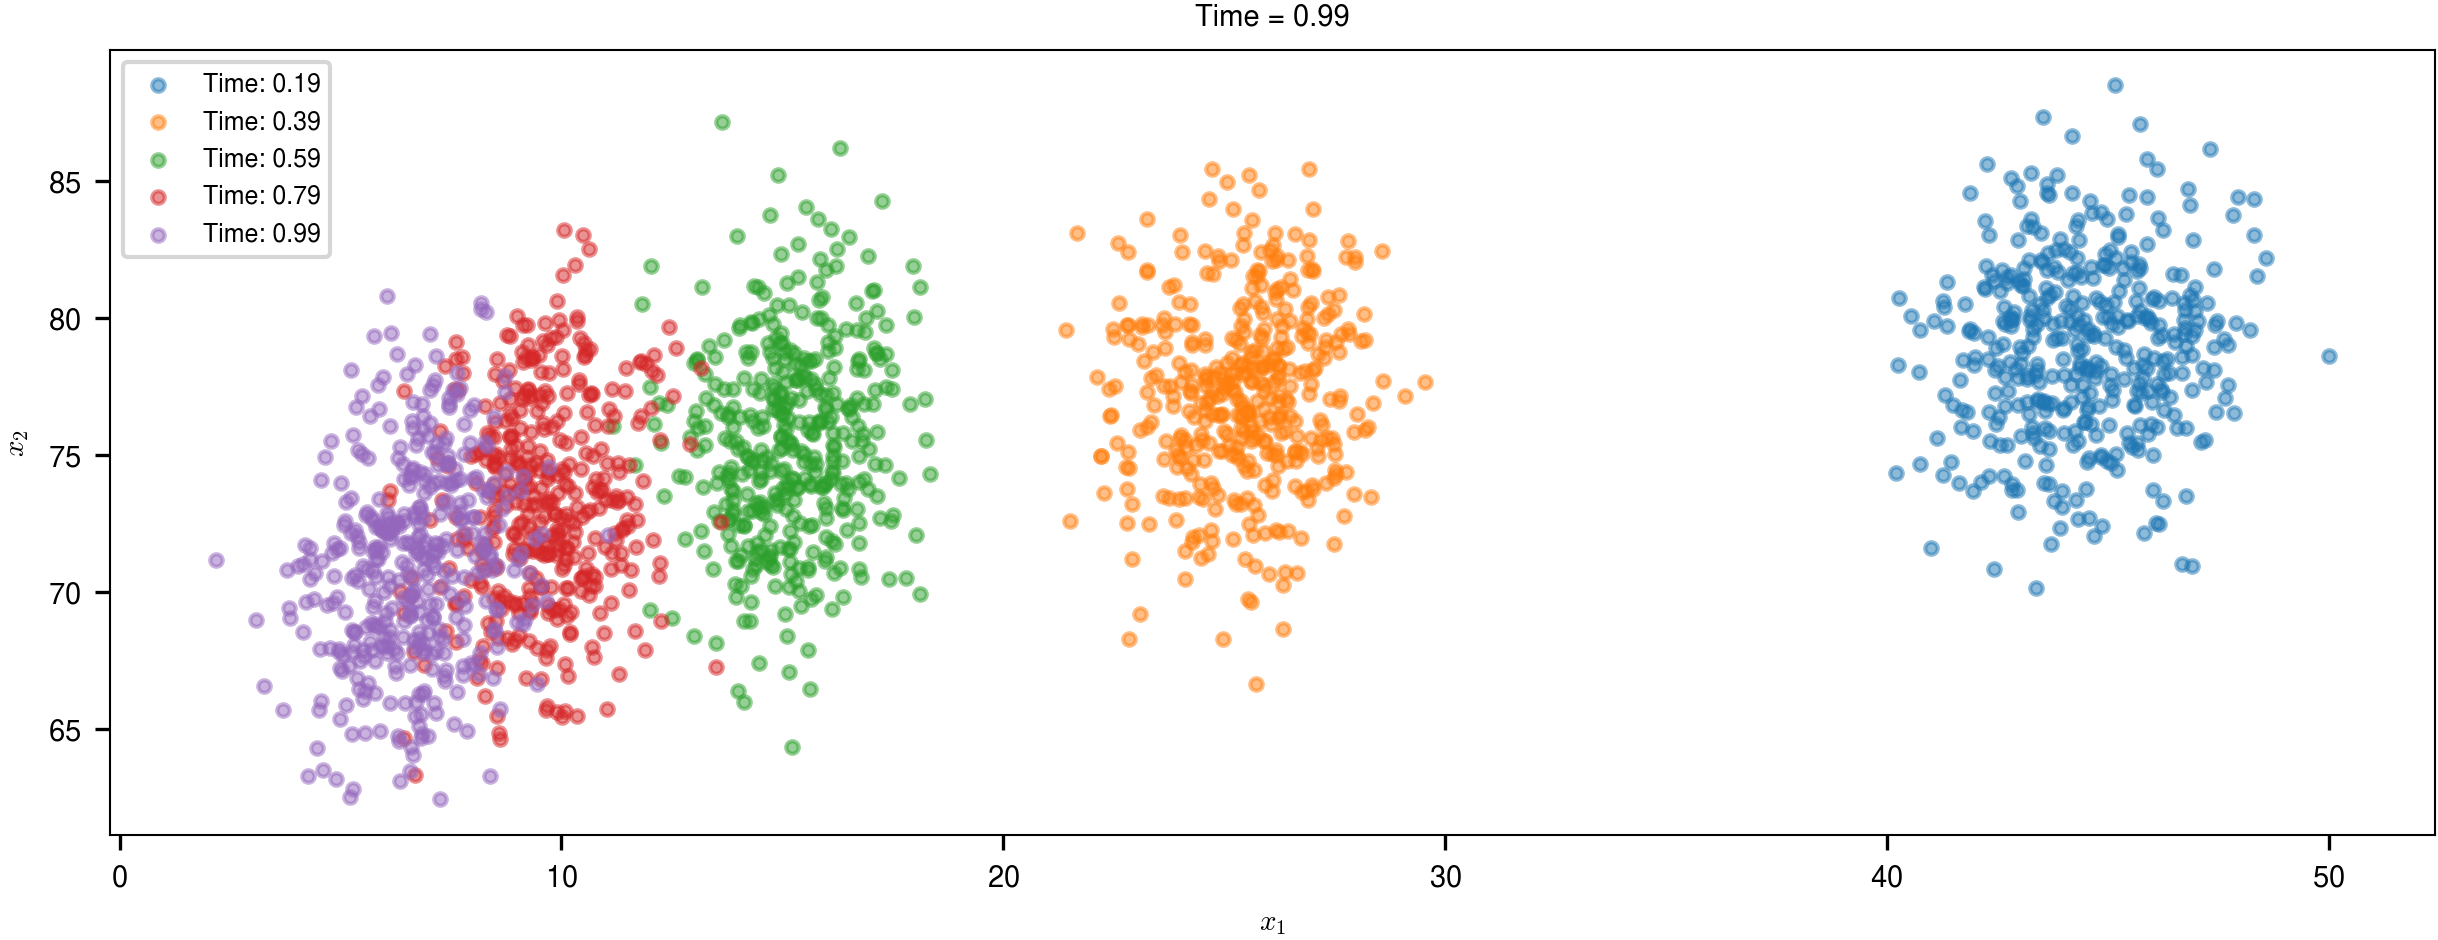

In [2]:
dt = 0.01
Dt = 0.2
nsnaps = 5
nsamples = 4000
D = 5.0
ndim = 2

np.random.seed(7)
A = np.random.randn(2, 2)
B = A @ A.T
eigval, _ = np.linalg.eig(B)

m0 = 80*np.ones((ndim), dtype=np.float32)
S0 = 8.0

samples_full, tt = simulate_ornstein_uhlenbeck(
    Om=B,
    D=D*np.eye(ndim),
    m0=m0,
    S0=S0,
    nsamples=nsamples,
    ndim=ndim,
    Dt=Dt,
    K=nsnaps,
    dt=dt,
)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10,3.4))

for k in range(0, nsnaps):
    ind_s = np.arange(0,samples_full[k].shape[0])
    np.random.shuffle(ind_s)
    ax.scatter(samples_full[k][ind_s[0:400],0],
                samples_full[k][ind_s[0:400],1],
                alpha=0.5,label='Time: '+str(tt[k]))
    ax.legend(loc='best')

    ax.set_title(r'Time = '+ str(np.round(tt[k],3)))
    ax.set_xlabel(r'$x_1$')
    ax.set_ylabel(r'$x_2$')
plt.show()

batch_ot_samples torch.Size([5, 4000, 2])


/tmp/ipykernel_1606940/1208466967.py:20: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch_ot_samples = torch.tensor(batch_ot_samples, dtype=torch.float32)


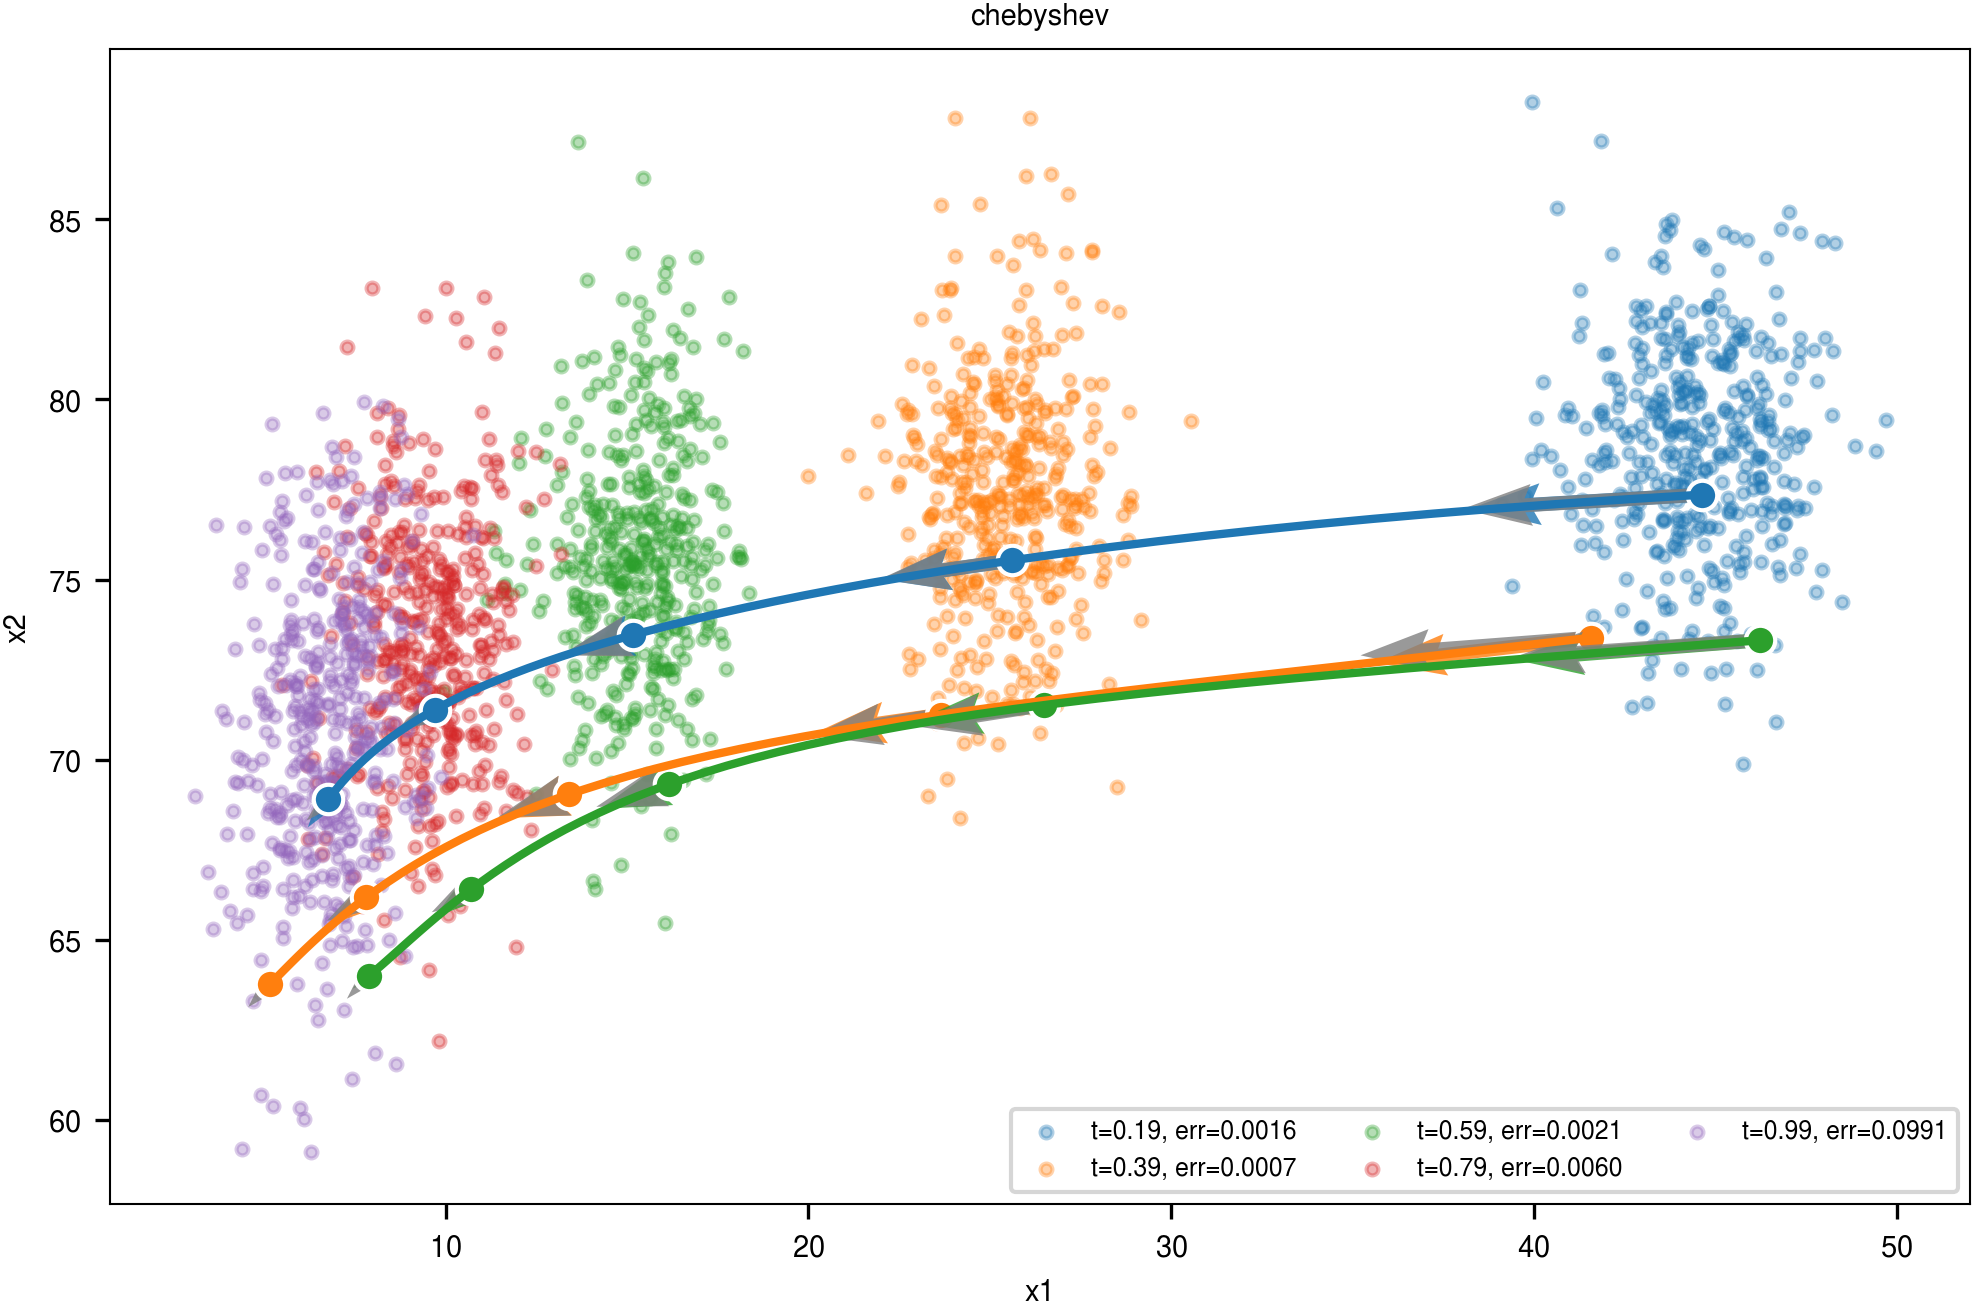

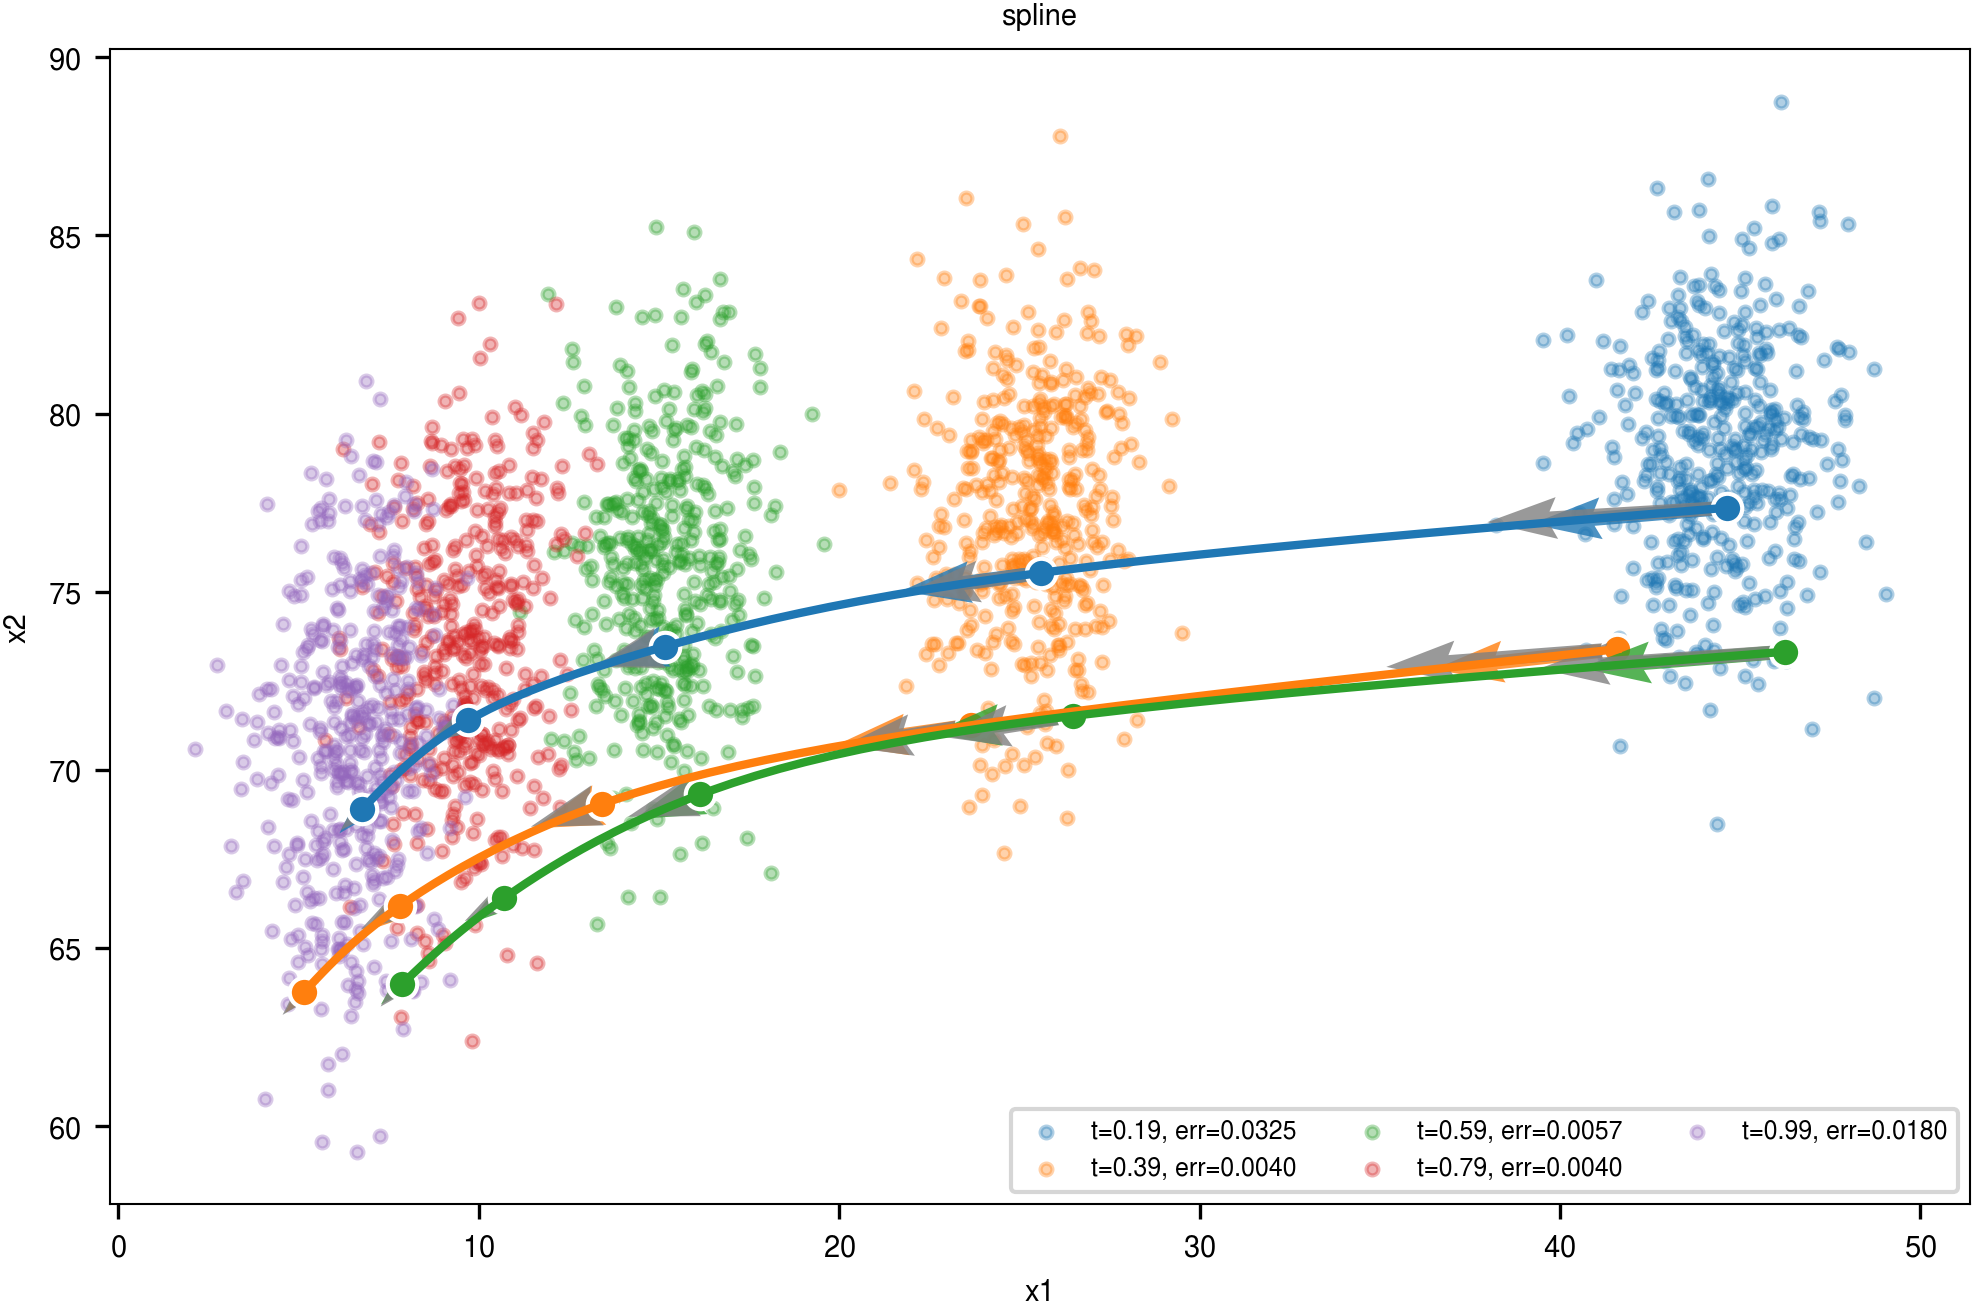

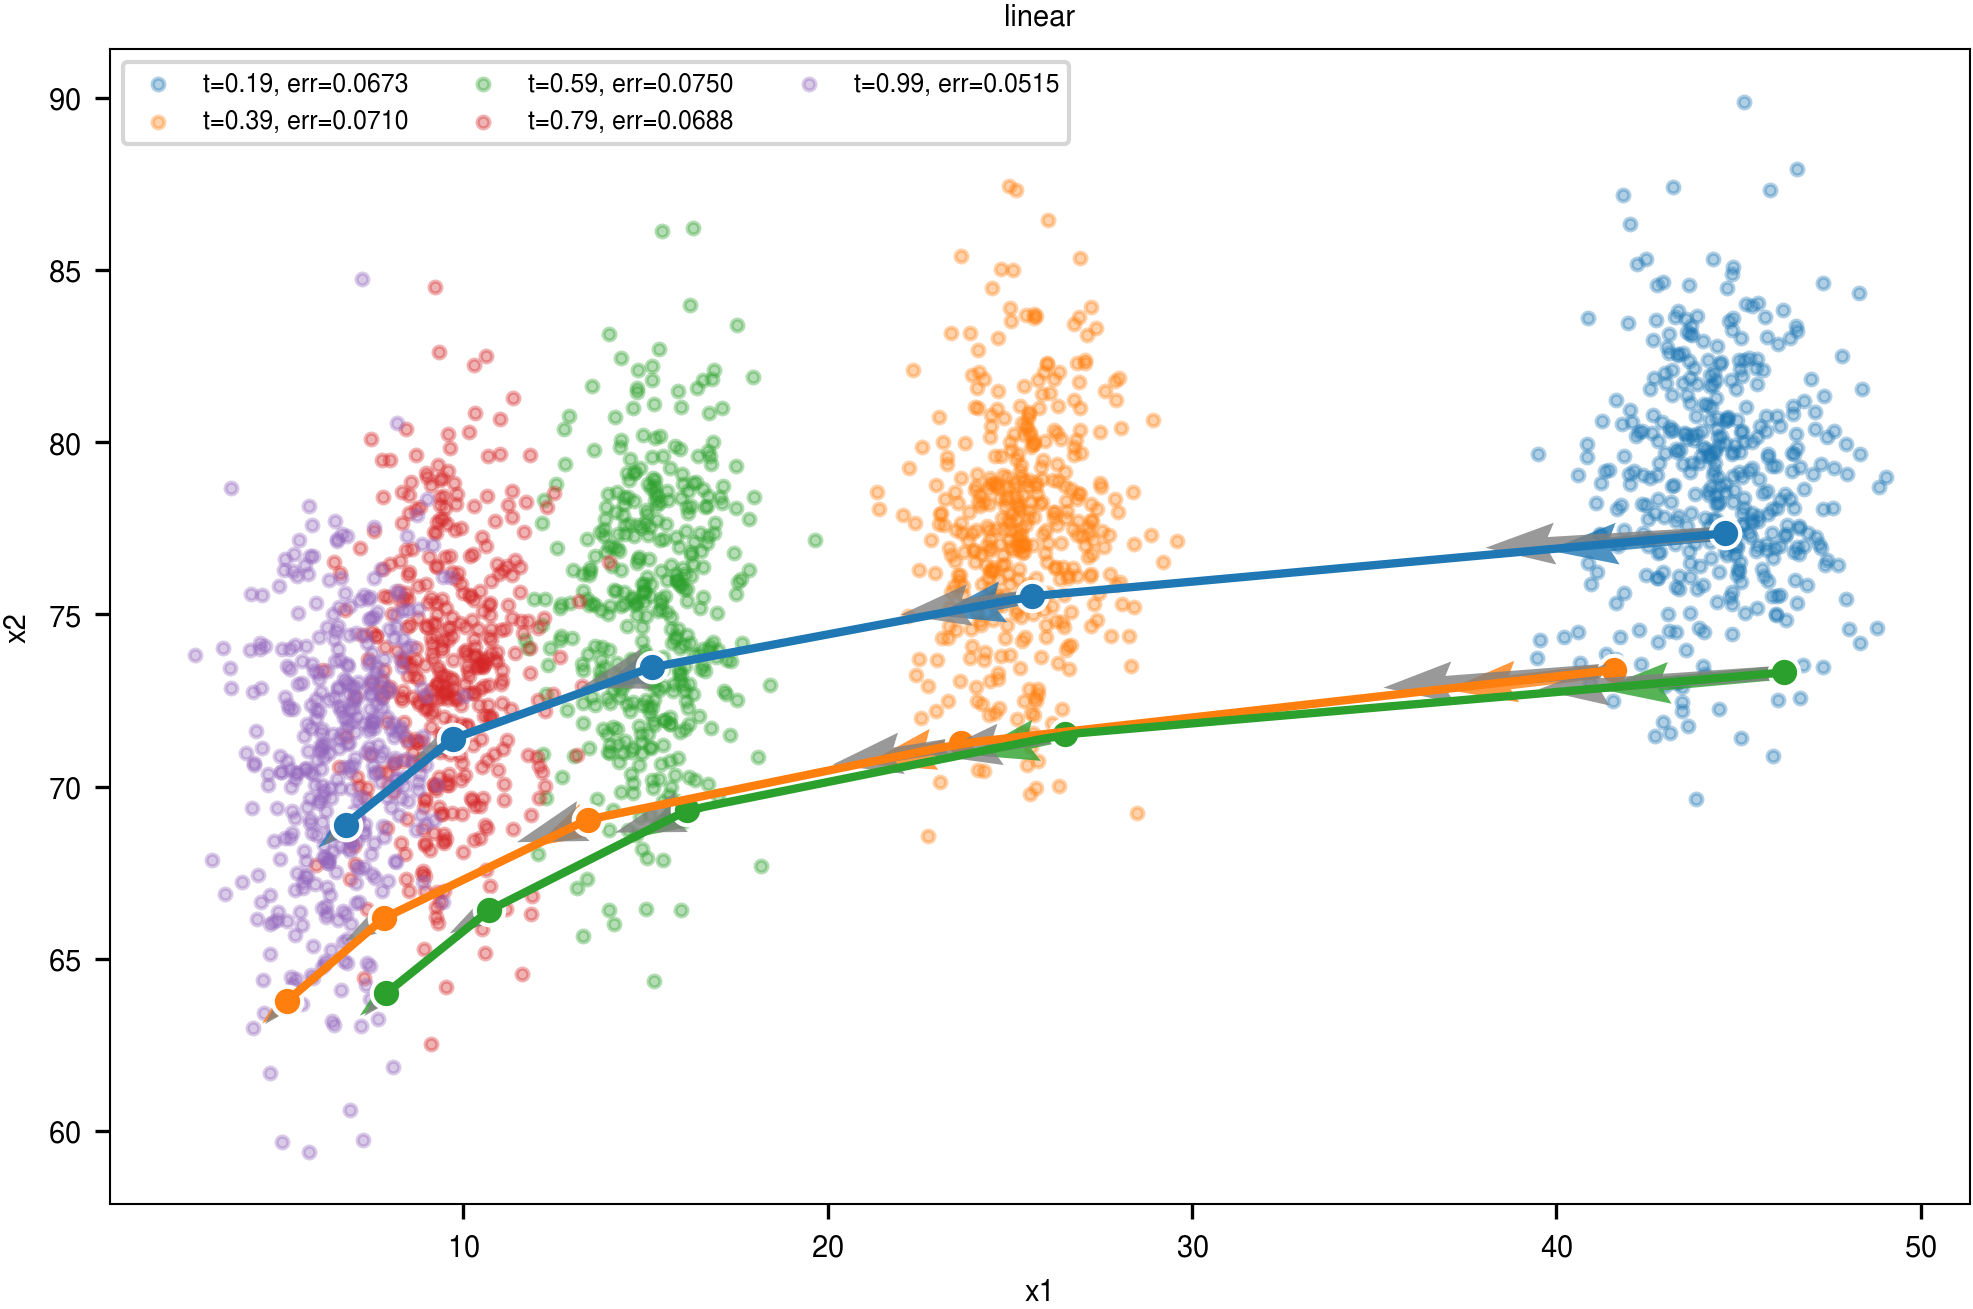

In [4]:
from pfi.utils.data import X_from_snapshots, snapshots_from_X
from pfi.flow.interpolants import ChebyshevInterpolant, LinearInterpolant, SplineInterpolant
from pfi.flow.models import OUFlow
from pfi.score.models import OUScore
from pfi.utils.nns import ConstantNN, LinearNN


# Build OT trajectories (MMOT)
np.random.seed(0)
X = X_from_snapshots(samples_full, tt)

snaps, _ = snapshots_from_X(X)
batch_ot_samples, _ = ExactOT().fit(snaps).sample()
print('batch_ot_samples', batch_ot_samples.shape)

# Nodes of the data and to evaluate the interpolant
npoints = 50
nodes_fit = torch.tensor(tt, dtype=torch.float32)[None, :].repeat(nsamples, 1)
nodes_eval = torch.tensor(np.linspace(tt[0], tt[-1], npoints), dtype=torch.float32)[None, :].repeat(nsamples, 1)

# Data must be in the format nsamples x nsnaps x ndim
batch_ot_samples = torch.tensor(batch_ot_samples, dtype=torch.float32)
dist = torch.permute(batch_ot_samples[:, :, 0:ndim], (1, 0, 2))

interpolants = {
    'chebyshev': ChebyshevInterpolant(),
    'spline': SplineInterpolant(),
    'linear': LinearInterpolant()
}

# Construct the analytical true flow model
X_ = X_from_snapshots([dist.cpu().numpy()[:,k,:] for k in range(nsnaps)], tt)
B_ = torch.tensor(B, dtype=torch.float32)
m0_ = torch.tensor(m0, dtype=torch.float32) 
S0_ = torch.tensor(np.eye(ndim)*S0, dtype=torch.float32)
D_ = torch.tensor(np.eye(ndim)*D, dtype=torch.float32)

true_score = OUScore(m0=m0_, 
                     S0=S0_, 
                     D=D_)
true_score.Ndim_ = ndim
true_score.net_ = ConstantNN([ndim, ndim])
with torch.no_grad():
    true_score.net_.B.copy_(B_)

true_flow = OUFlow(score=true_score,
                   D=D_)
true_flow.Ndim_ = ndim
true_flow.net_ = LinearNN([ndim, ndim])
with torch.no_grad():
    true_flow.net_.B.copy_(B_)

dx_flow = (true_flow(torch.tensor(X_, dtype=torch.float32))
                    .reshape(nsnaps, nsamples, ndim)
                    .permute(1,0,2).detach().cpu().numpy())

for name, interpolant in interpolants.items():

    interpolant.fit(nodes_fit, dist)
    x_train = interpolant.y_fit_.cpu().numpy()

    x_interp, _ = interpolant.predict(nodes_eval)
    _, dx_interp_data = interpolant.predict(nodes_fit)

    fig, ax = plt.subplots(1, 1, figsize=(8, 5))
    colors = ['tab:blue', 'tab:orange', 'tab:green']


    x_interp = x_interp.cpu().numpy()
    dx_interp_data = dx_interp_data.cpu().numpy()
    average_rel_err = np.mean(((dx_flow - dx_interp_data)**2).sum(axis = -1)/((dx_flow)**2).sum(axis = -1), axis=0)

    for k in range(nsnaps):
        xk = samples_full[k]
        ind = np.arange(xk.shape[0])
        np.random.shuffle(ind)
        ax.scatter(xk[ind[:400], 0], xk[ind[:400], 1], s=8, alpha=0.35, 
                   label='t=%.2f, err=%.4f' % (tt[k], average_rel_err[k]))

    for i in range(3):

        ax.plot(x_interp[i, :, 0], x_interp[i, :, 1], color=colors[i], linewidth=2)
        ax.quiver(x_train[i, :, 0], x_train[i, :, 1],
                 dx_interp_data[i, :, 0], dx_interp_data[i, :, 1], color=colors[i], alpha = 0.8, linewidth=2, scale=1000)
        ax.quiver(dist[i, :, 0].cpu().numpy(), dist[i, :, 1].cpu().numpy(),
                 dx_flow[i, :, 0], dx_flow[i, :, 1], alpha = 0.8, color='grey', linewidth=2, scale=1000)
        ax.scatter(x_train[i, :, 0], x_train[i, :, 1], s=50, color=colors[i], edgecolor='white')

    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.legend(loc='best', ncol=3)
    ax.set_title('%s' % (name))
    plt.show()

